# 线性回归实验

***

## 主要内容
* 线性回归方程实现
* 梯度下降效果
* 对比不同下降策略
* 建模曲线分析
* 过拟合与欠拟合
* 正则化的作用
* 提前停止策略

In [1]:
import os
%matplotlib inline
import matplotlib
import matplotlib.pyplot as plt
plt.rcParams['axes.labelsize'] = 14
plt.rcParams['xtick.labelsize'] = 12
plt.rcParams['ytick.labelsize'] = 12
import warnings
warnings.filterwarnings('ignore')  
import numpy as np
np.random.seed(42) 

***
## 1. 线性回归方程实现

**回归方程**

<div align="center">
  <img src="./img/线性回归公式.png" width="1500"/>
</div>

**实验目标**
* 在之前原理部分，我们推导了最小二乘法及其求解
* 接下来我们要实验的就是我们这个最小二乘法到底能不能算出这个 $\theta$
* 这是一个初始的方法，这不是机器学习的思想

**代码实现**

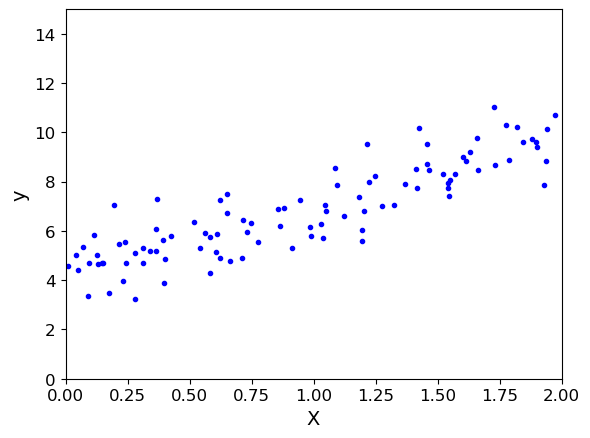

In [2]:
# 构造一份实验使用的数据
import numpy as np
np.random.seed(42)       
X = 2*np.random.rand(100,1)     # 添加随机抖动
y = 4 + 3*X + np.random.randn(100,1) # 添加随机抖动

# 绘制数据点阵图
plt.plot(X, y, 'b.')
plt.xlabel('X')
plt.ylabel('y')
plt.axis([0, 2, 0,15])
plt.show()

In [3]:
# 已知数据求参数
X_b = np.c_[(np.ones((100,1))), X]      # numpy拼接一列（全为1）: ones(shape, dtype, order, like)
print(X_b[:5])

theta_best = np.linalg.inv(X_b.T.dot(X_b)).dot(X_b.T).dot(y)  # 公式
print(theta_best)   # 两项：偏置项 + 权重项

[[1.         0.74908024]
 [1.         1.90142861]
 [1.         1.46398788]
 [1.         1.19731697]
 [1.         0.31203728]]
[[4.21509616]
 [2.77011339]]


In [4]:
# 新数据预测画出回归线
X_new = np.array([[0],[2]])
X_new_b = np.c_[(np.ones((2,1))), X_new]   # 需要和训练集有同样的数据处理操作
y_predict = X_new_b.dot(theta_best)
print(y_predict) 

[[4.21509616]
 [9.75532293]]


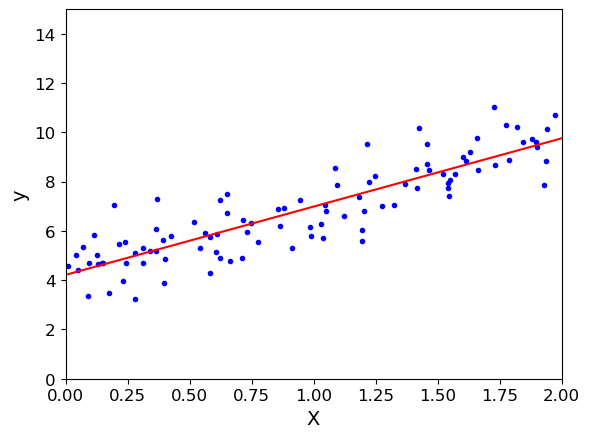

In [5]:
plt.plot(X, y, 'b.')
plt.plot(X_new, y_predict, 'r-')
plt.xlabel('X')
plt.ylabel('y')
plt.axis([0, 2, 0,15])
plt.show()

**利用sklearnAPI完成**
* https://scikit-learn.org/stable/api/index.html

In [6]:
from sklearn.linear_model import LinearRegression
lin_reg = LinearRegression()
lin_reg.fit(X,y)
print (lin_reg.coef_)
print (lin_reg.intercept_)

[[2.77011339]]
[4.21509616]


***
## 2. 梯度下降对比（学习率差异+不同梯度下降算法）

**梯度下降原理图**
<div align="center">
  <img src="./img/梯度下降原理图.png" width="1200"/>
</div>

**学习率差异**

* 步长过小/过大与收敛
  <table>
  <tr>
    <td><img src="./img/步长过小.png" width="300"></td>
    <td><img src="./img/步长过大.png" width="300"></td>
    <td><img src="./img/收敛问题.png" width="300"></td>
  </tr>
</table>

**a.批量梯度下降(同时实验学习率的差异）**
<div align="center">
  <img src="./img/批量梯度下降.png" width="1100"/>
</div>

In [7]:
# 通过梯度去迭代计算参数
eta = 0.2
n_iterations = 1000
m = 100
theta = np.random.randn(2,1)    # 随机初始化，从标准正态分布里抽
for i in range(n_iterations):
    gradients = 2/m*X_b.T.dot(X_b.dot(theta)-y)
    theta = theta - eta*gradients
theta

array([[4.21509616],
       [2.77011339]])

In [8]:
y_pre = X_new_b.dot(theta)
y_pre

array([[4.21509616],
       [9.75532293]])

In [9]:
# 不同的学习率得到的结果
theta_path_bgd = []
def plot_gradient_descent(theta, eta, theta_path=None):
    m = len(X_b)
    plt.plot(X, y, 'b.')
    n_iterations = 1000
    for i in range(n_iterations):
        y_predict = X_new_b.dot(theta)
        plt.plot(X_new, y_predict, 'r-') 
        gradients = 1/m*X_b.T.dot(X_b.dot(theta)-y)   #批量梯度
        theta = theta - eta*gradients
        if theta_path is not None:
            theta_path.append(theta.copy())
    plt.xlabel('X_1')
    plt.axis([0,2,0,15])
    plt.title('eta = {}'.format(eta))

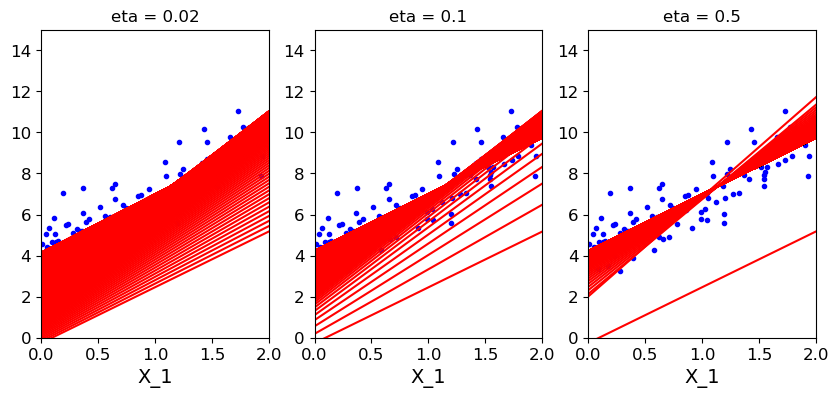

In [10]:
theta = np.random.randn(2,1)

plt.figure(figsize=(10,4))
plt.subplot(131)
plot_gradient_descent(theta, eta = 0.02)
plt.subplot(132)
plot_gradient_descent(theta, eta = 0.1, theta_path = theta_path_bgd)
plt.subplot(133)
plot_gradient_descent(theta, eta = 0.5)
plt.show()

**b.随机梯度下降**

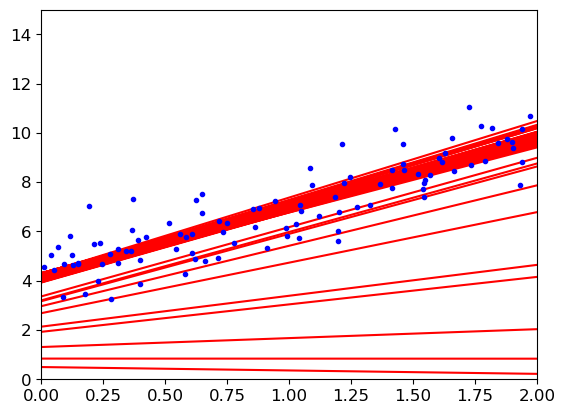

In [11]:
# 随机梯度下降
theta_path_sgd = []
m = len(X_b)
n_epochs = 50

np.random.seed(42)

# 学习率衰减
t0 = 20
t1 = 200
def learning_schedule(t):
    return t0/(t1+t)

theta = np.random.randn(2,1)

for epoch in range(n_epochs):
    for i in range(m):
        if epoch < 30 and i < 10:     
            y_predict = X_new_b.dot(theta)
            plt.plot(X_new, y_predict, 'r-') 
        random_index = np.random.randint(m)
        Xi = X_b[random_index:random_index+1]
        yi = y[random_index:random_index+1]
        gradients = Xi.T.dot(Xi.dot(theta)-yi)   #随机梯度
        eta = learning_schedule(epoch*m+i)
        theta = theta - eta*gradients
        theta_path_sgd.append(theta.copy())

plt.plot(X,y,'b.')
plt.axis([0,2,0,15])
plt.show()

**c.小批量梯度下降**

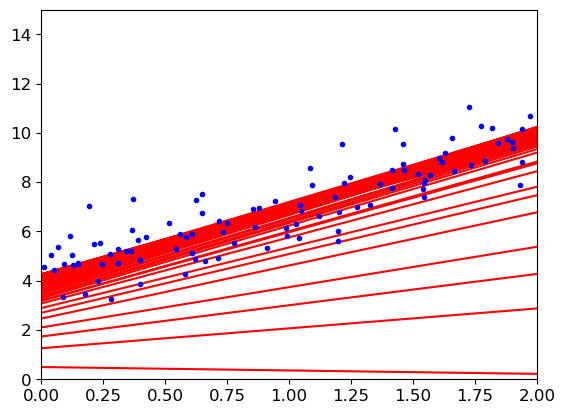

In [12]:
theta_path_mgd=[]
n_epoch = 50
minibatch = 5
np.random.seed(42)
theta = np.random.randn(2,1)
t=0

for epoch in range(n_epoch):
    shuffled_indices = np.random.permutation(m)
    X_b_shuffled = X_b[shuffled_indices]
    y_shuffled = y[shuffled_indices]
    for i in range(0,m,minibatch):
        t+=1
        Xi = X_b_shuffled[i:i+minibatch]
        yi = y_shuffled[i:i+minibatch]
        y_predict = X_new_b.dot(theta)
        plt.plot(X_new, y_predict, 'r-') 
        gradients = 1/minibatch*Xi.T.dot(Xi.dot(theta)-yi)
        eta = learning_schedule(t)
        theta = theta-eta*gradients
        theta_path_mgd.append(theta.copy())

plt.plot(X,y,'b.')
plt.axis([0,2,0,15])
plt.show()

**d.san zho不同梯度下降算法的对比**

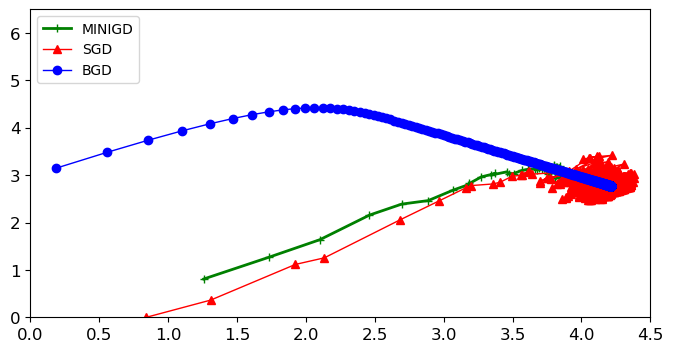

In [13]:
theta_path_bgd = np.array(theta_path_bgd)
theta_path_sgd = np.array(theta_path_sgd)
theta_path_mgd = np.array(theta_path_mgd)


plt.figure(figsize=(8,4))
plt.plot(theta_path_mgd[:,0],theta_path_mgd[:,1],'g-+',linewidth=2,label="MINIGD")
plt.plot(theta_path_sgd[:,0],theta_path_sgd[:,1],'r-^',linewidth=1,label="SGD")
plt.plot(theta_path_bgd[:,0],theta_path_bgd[:,1],'b-o',linewidth=1,label="BGD")
plt.legend(loc='upper left')
plt.axis([0,4.5,0,6.5])
plt.show()

# bgd线没有那么平直是因为没有标准化，但是用了randn其实已经是比较标准化的情况了，可以忽略这个问题

## 3. 多项式回归

**工具包**
* 概念
    * PolynomialFeatures 是 sklearn 里用来把原始特征“升维”成多项式组合的工具。一句话：让线性模型能拟合曲线。
    * 它不改变算法，只是“改造数据”，让线性模型看到更丰富的特征，从而画出曲线。
* 参数
    * degree=2(默认): 多项式最高次数
    * interaction_only=False(默认):	只要交叉项，不要平方项
    * include_bias=True(默认)：要不要加全 1 的截距列
    * order=(默认)：'C'输出顺序（几乎不用改）

In [14]:
# 生成数据点
np.random.seed(42)
m = 100
X = 6*np.random.rand(m,1)-3
y = 0.5*X**2+X+np.random.randn(m,1)

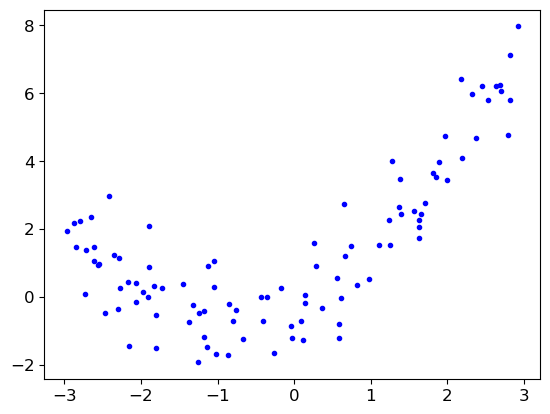

In [15]:
plt.plot(X,y,'b.') 
plt.show()

In [16]:
from sklearn.preprocessing import PolynomialFeatures
poly_features = PolynomialFeatures(degree = 2, include_bias = False)

X_poly = poly_features.fit_transform(X)

In [17]:
from sklearn.linear_model import LinearRegression
lin_reg = LinearRegression()
lin_reg.fit(X_poly, y)
print (lin_reg.coef_)
print (lin_reg.intercept_)

[[0.93366893 0.56456263]]
[-0.21865419]


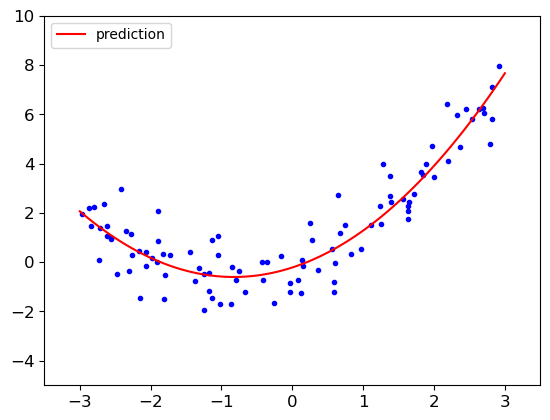

In [18]:
X_new = np.linspace(-3,3,100).reshape(100,1)
X_new_poly = poly_features.transform(X_new)
y_new = lin_reg.predict(X_new_poly)
plt.plot(X, y,'b.')
plt.plot(X_new, y_new,'r-',label='prediction')
plt.axis([-3.5,3.5,-5,10])
plt.legend(loc='upper left')
plt.show()

**观察不通次幂画出图像的差异**
* 步骤
    1. 计算PolynomialFeatures
    2. 标准化
    3. 建模
* sklearn API：pipline模块

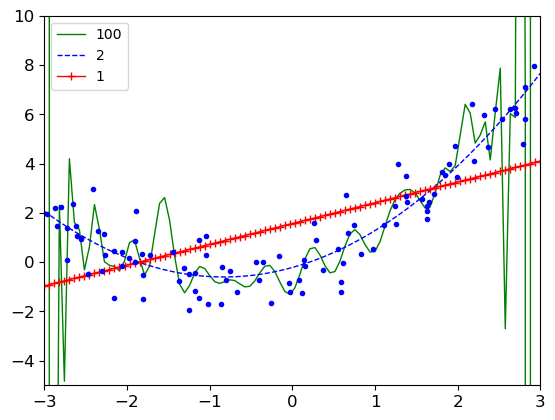

In [19]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

for style, width, degree in (('g-',1,100),('b--',1,2),('r-+',1,1)):
    poly_features = PolynomialFeatures(degree = degree, include_bias = False)
    std = StandardScaler()
    lin_reg = LinearRegression()
    polynomial_reg = Pipeline([('poly_features',poly_features),
             ('StandardScaler',std),
             ('lin_reg',lin_reg)])
    polynomial_reg.fit(X,y)
    y_new_2 = polynomial_reg.predict(X_new)
    plt.plot(X_new,y_new_2,style,label = str(degree),linewidth = width)

plt.plot(X, y,'b.')
plt.axis([-3,3,-5,10])
plt.legend(loc='upper left')
plt.show()

## 4.样本数量对结果的影响

In [24]:
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split

def plot_learning_curves(model,X,y):
    X_train, X_val, y_train, y_val = train_test_split(X,y,test_size = 0.2,random_state=100)
    train_errors,val_errors = [],[]
    for m in range(1,len(X_train)):
        model.fit(X_train[:m],y_train[:m])
        y_train_predict = model.predict(X_train[:m])
        y_val_predict = model.predict(X_val)
        train_errors.append(mean_squared_error(y_train[:m],y_train_predict[:m]))
        val_errors.append(mean_squared_error(y_val,y_val_predict))
    plt.plot(np.sqrt(train_errors),'r-+',linewidth = 2,label = 'train_error')
    plt.plot(np.sqrt(val_errors),'b-',linewidth = 3,label = 'val_error')
    plt.xlabel('Trainsing set size')
    plt.ylabel('RMSE')
    plt.legend()

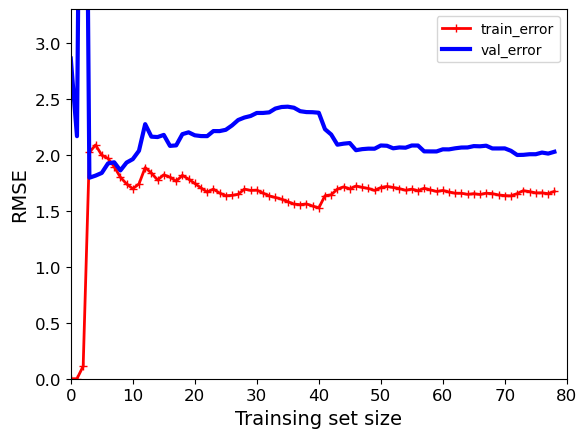

In [25]:
lin_reg = LinearRegression()
plot_learning_curves(lin_reg,X,y)
plt.axis([0,80,0,3.3])
plt.show()

## 5. 多项式回归过拟合风险

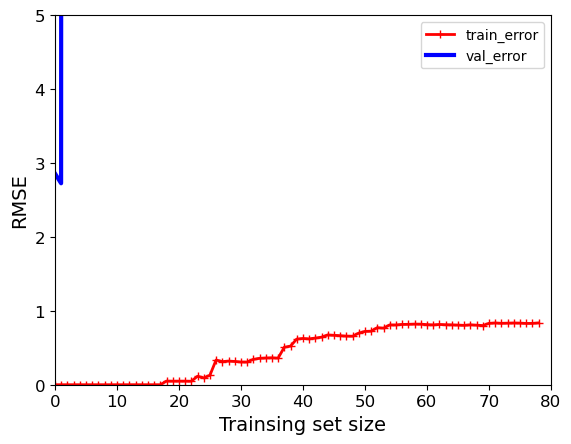

In [26]:
polynomial_reg = Pipeline([('poly_features',PolynomialFeatures(degree = 25,include_bias = False)),
             ('lin_reg',LinearRegression())])
plot_learning_curves(polynomial_reg,X,y)
plt.axis([0,80,0,5])
plt.show()

## 6. 正则化
对权重参数进行惩罚，让权重参数尽可能平滑一些，有两种不同的方法来进行正则化惩罚:

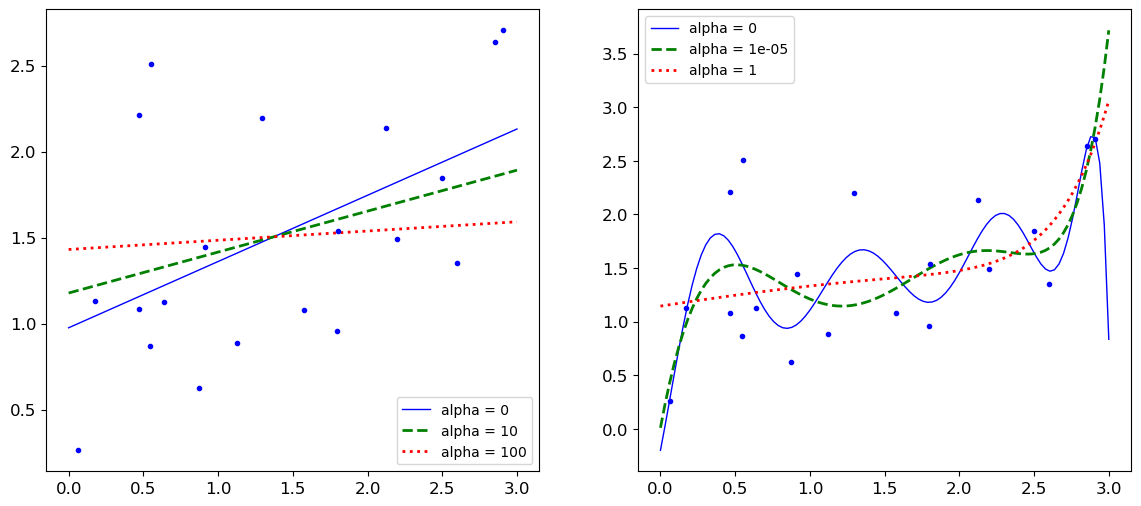

In [27]:
from sklearn.linear_model import Ridge
np.random.seed(42)
m = 20
X = 3*np.random.rand(m,1)
y = 0.5 * X +np.random.randn(m,1)/1.5 +1
X_new = np.linspace(0,3,100).reshape(100,1)

def plot_model(model_calss,polynomial,alphas,**model_kargs):
    for alpha,style in zip(alphas,('b-','g--','r:')):
        model = model_calss(alpha,**model_kargs)
        if polynomial:
            model = Pipeline([('poly_features',PolynomialFeatures(degree =10,include_bias = False)),
             ('StandardScaler',StandardScaler()),
             ('lin_reg',model)])
        model.fit(X,y)
        y_new_regul = model.predict(X_new)
        lw = 2 if alpha > 0 else 1
        plt.plot(X_new,y_new_regul,style,linewidth = lw,label = 'alpha = {}'.format(alpha))
    plt.plot(X,y,'b.',linewidth =3)
    plt.legend()

plt.figure(figsize=(14,6))
plt.subplot(121)
plot_model(Ridge,polynomial=False,alphas = (0,10,100))
plt.subplot(122)
plot_model(Ridge,polynomial=True,alphas = (0,10**-5,1))
plt.show()

惩罚力度越大，alpha值越大的时候，得到的决策方程越平稳。

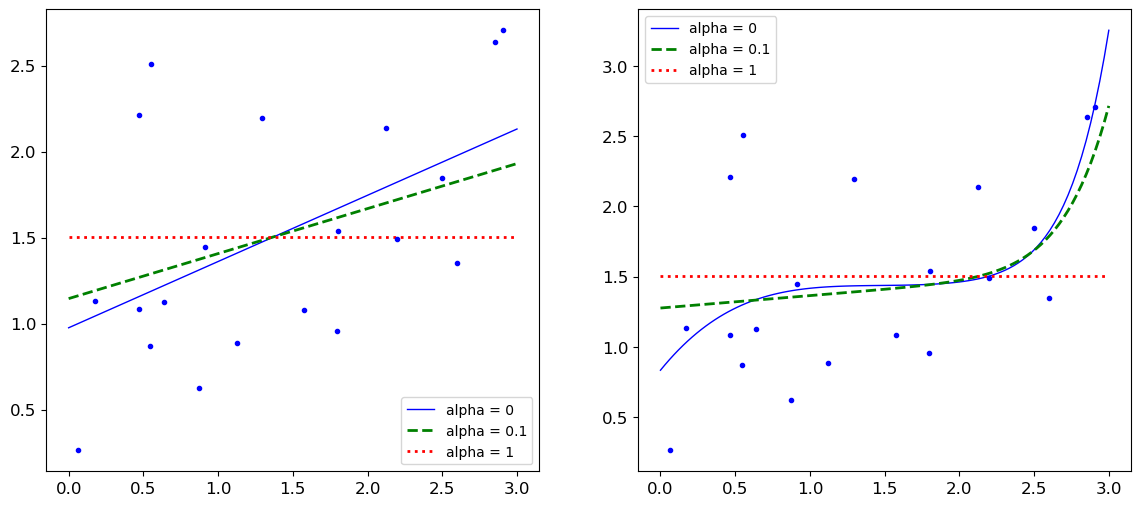

In [28]:
from sklearn.linear_model import Lasso

plt.figure(figsize=(14,6))
plt.subplot(121)
plot_model(Lasso,polynomial=False,alphas = (0,0.1,1))
plt.subplot(122)
plot_model(Lasso,polynomial=True,alphas = (0,10**-1,1))
plt.show()